# Baseline: Faster R-CNN (ResNet-50 + FPN) - Fire & Smoke Detection

**Scope:**
- Model config (Faster R-CNN ResNet-50 + FPN, COCO pretrained, 2 classes + background)
- Training setup (SGD + cosine annealing, hyperparameters)
- Full training loop with checkpointing (best by val mAP@0.5:0.95), early stopping, resume
- Sanity check that the baseline model trains and produces predictions
- Training logs (JSON + loss/mAP curves) for the report

In [1]:
!pip install -q pyyaml tqdm torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.9 MB/s eta 0:00:00


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("linxel/dfire-prepared")

print("Path to dataset files:", path)

100%|██████████| 2.84G/2.84G [00:34<00:00, 89.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/linxel/dfire-prepared/versions/1


In [3]:
import os, sys, json, time, random, platform
from pathlib import Path
os.environ.pop('MASTER_ADDR', None)
os.environ.pop('MASTER_PORT', None)

import numpy as np
import torch
import torchvision
from PIL import Image
import yaml

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Platform     :", platform.platform())
print("Python       :", sys.version.split()[0])
print("PyTorch      :", torch.__version__)
print("Torchvision  :", torchvision.__version__)
print("CUDA         :", torch.version.cuda)
print("Device       :", device)
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("GPU memory   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

Platform     : Linux-6.6.122+-x86_64-with-glibc2.39
Python       : 3.13.15
PyTorch      : 2.11.0+cu130
Torchvision  : 0.26.0+cu130
CUDA         : 13.0
Device       : cuda
GPU          : Tesla T4
GPU memory   : 15.6 GB


In [4]:
from pathlib import Path

# Твой новый путь из Colab
DATA_ROOT = Path("/root/.cache/kagglehub/datasets/linxel/dfire-prepared/versions/1")

print("ROOT exists:", DATA_ROOT.exists())
if DATA_ROOT.exists():
    print("Contents:", [p.name for p in DATA_ROOT.iterdir()])

    data_dir = DATA_ROOT / "data"
    if data_dir.exists():
        for split_dir in data_dir.iterdir():
            if split_dir.is_dir():
                print(f"  {split_dir.name}/ -> {[p.name for p in split_dir.iterdir()]}")

ROOT exists: True
Contents: ['data']
  test/ -> ['images', 'labels']
  val/ -> ['images', 'labels']
  train/ -> ['images', 'labels']


In [5]:
from pathlib import Path
import json
import os, sys, time, random
import numpy as np
import torch
import torchvision

DATA_ROOT = Path("/root/.cache/kagglehub/datasets/linxel/dfire-prepared/versions/1")

CKPT_DIR = Path("/content/checkpoints/faster_rcnn")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

data_yaml = {
    "path": str(DATA_ROOT / "data"),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {0: "smoke", 1: "fire"},
    "nc": 2,
}
print("\ndata.yaml:")
print(json.dumps(data_yaml, indent=2))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

CONFIG = {
    "model": "fasterrcnn_resnet50_fpn",
    "pretrained": "COCO_V1",
    "num_classes": 3,
    "input_size": 640,
    "optimizer": "SGD",
    "lr": 5e-3,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "scheduler": "CosineAnnealingLR",
    "epochs": 6,
    "batch_size": 4,
    "early_stopping_patience": 3,
    "grad_clip_max_norm": 10.0,
    "augmentation": ["horizontal_flip_p0.5"],
    "seed": SEED,
    "num_workers": 2,
}

names = data_yaml["names"]
names = {int(k): v for k, v in names.items()}
assert names == {0: "smoke", 1: "fire"}, f"Unexpected class mapping: {names}"
assert data_yaml["nc"] == 2, "Expected nc=2"
print("\nClass mapping verified:", names)

for split in ("train", "val", "test"):
    img_dir = DATA_ROOT / "data" / split / "images"
    lbl_dir = DATA_ROOT / "data" / split / "labels"

    if img_dir.is_dir():
        n_imgs = len([p for p in img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}])
        status = "OK" if lbl_dir.is_dir() else "NO LABELS DIR!"
        n_lbls = len(list(lbl_dir.iterdir())) if lbl_dir.is_dir() else 0
        print(f"{split:>5}: {n_imgs} images, {n_lbls} labels  [{status}]")
    else:
        print(f"{split:>5}: DIR NOT FOUND ({img_dir})")


data.yaml:
{
  "path": "/root/.cache/kagglehub/datasets/linxel/dfire-prepared/versions/1/data",
  "train": "train/images",
  "val": "val/images",
  "test": "test/images",
  "names": {
    "0": "smoke",
    "1": "fire"
  },
  "nc": 2
}
Device: cuda

Class mapping verified: {0: 'smoke', 1: 'fire'}
train: 14122 images, 14122 labels  [OK]
  val: 3099 images, 3099 labels  [OK]
 test: 4306 images, 4306 labels  [OK]


In [6]:
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T2
import torchvision.tv_tensors as tv_tensors


class FireSmokeDataset(Dataset):
    IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    def __init__(self, root: Path, split: str, flip_p: float = 0.0):
        self.root = Path(root)
        self.split = split
        self.flip_p = float(flip_p)
        self.images_dir = self.root / "data" / split / "images"
        self.labels_dir = self.root / "data" / split / "labels"
        if not self.images_dir.is_dir():
            raise FileNotFoundError(f"Missing {self.images_dir}")
        self.image_files = sorted(
            p for p in self.images_dir.iterdir()
            if p.is_file() and p.suffix.lower() in self.IMG_EXTS
        )
        self._to_tensor = T.ToTensor()

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        img = Image.open(img_path).convert("RGB")
        w, h = img.size

        label_path = self.labels_dir / (img_path.stem + ".txt")
        boxes, labels = [], []

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                x1 = (xc - bw / 2) * w
                y1 = (yc - bh / 2) * h
                x2 = (xc + bw / 2) * w
                y2 = (yc + bh / 2) * h
                x1, y1 = max(0.0, x1), max(0.0, y1)
                x2, y2 = min(w, x2), min(h, y2)
                if x2 <= x1 or y2 <= y1:
                    continue
                boxes.append([x1, y1, x2, y2])
                # YOLO 0=smoke,1=fire -> torchvision 1=smoke,2=fire
                labels.append(1 if int(cls) == 0 else 2)

        img_t = self._to_tensor(img)  # float [0,1], (3,H,W)
        boxes_t = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels_t = torch.as_tensor(labels, dtype=torch.int64)
        if self.flip_p > 0.0 and torch.rand(1).item() < self.flip_p:
            img_t = torch.flip(img_t, dims=[-1])  # (3,H,W) -> flip width
            if boxes_t.numel() > 0:
                x1_old = boxes_t[:, 0].clone()
                x2_old = boxes_t[:, 2].clone()
                boxes_t[:, 0] = w - x2_old
                boxes_t[:, 2] = w - x1_old

        area = (
            (boxes_t[:, 3] - boxes_t[:, 1]) * (boxes_t[:, 2] - boxes_t[:, 0])
            if boxes_t.numel() else torch.zeros((0,), dtype=torch.float32)
        )

        target = {
            "boxes": boxes_t,
            "labels": labels_t,
            "image_id": torch.tensor([idx]),
            "area": area,
            "iscrowd": torch.zeros((boxes_t.shape[0],), dtype=torch.int64),
        }
        return img_t, target


def collate_fn(batch):
    return tuple(zip(*batch))

In [7]:
print(FireSmokeDataset)
print(collate_fn)

<class '__main__.FireSmokeDataset'>
<function collate_fn at 0x7f4361cec400>


In [8]:
train_ds = FireSmokeDataset(DATA_ROOT, "train", flip_p=0.5)
val_ds = FireSmokeDataset(DATA_ROOT, "val",   flip_p=0.0)

print(f"Train images: {len(train_ds)}")
print(f"Val images  : {len(val_ds)}")

train_loader = DataLoader(
    train_ds, batch_size=CONFIG["batch_size"], shuffle=True,
    num_workers=CONFIG["num_workers"], collate_fn=collate_fn, pin_memory=True,
)
val_loader = DataLoader(
    val_ds, batch_size=CONFIG["batch_size"], shuffle=False,
    num_workers=CONFIG["num_workers"], collate_fn=collate_fn, pin_memory=True,
)

imgs, tgts = next(iter(train_loader))
print(f"One batch: {len(imgs)} images, image shape {tuple(imgs[0].shape)}, "
      f"boxes in first target: {tgts[0]['boxes'].shape[0]}, "
      f"labels: {tgts[0]['labels'].tolist()}")

Train images: 14122
Val images  : 3099
One batch: 4 images, image shape (3, 720, 1280), boxes in first target: 2, labels: [2, 2]


In [9]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights


def build_faster_rcnn(num_classes: int = 3, input_size: int = 640):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1
    )
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    model.transform.min_size = (input_size,)
    model.transform.max_size = input_size
    return model


model = build_faster_rcnn(CONFIG["num_classes"], CONFIG["input_size"]).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params/1e6:.2f} M")

model.eval()
with torch.no_grad():
    _ = model([imgs[0].to(device), imgs[1].to(device)])
print("Forward pass OK.")
model.train()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 160MB/s]


Trainable parameters: 41.08 M
Forward pass OK.


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(640,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(i

In [10]:
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.SGD(
    params, lr=CONFIG["lr"], momentum=CONFIG["momentum"],
    weight_decay=CONFIG["weight_decay"],
)
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)

print("Optimizer:", optimizer.__class__.__name__)
print("Scheduler:", scheduler.__class__.__name__)
print(f"LR: {CONFIG['lr']} -> 1e-6 (cosine), T_max={CONFIG['epochs']}")

Optimizer: SGD
Scheduler: CosineAnnealingLR
LR: 0.005 -> 1e-6 (cosine), T_max=6


In [11]:
from tqdm.auto import tqdm
from torchmetrics.detection import MeanAveragePrecision


def train_one_epoch(model, optimizer, loader, device, epoch, grad_clip=10.0):
    model.train()
    sums = {"loss": 0.0, "loss_classifier": 0.0, "loss_box_reg": 0.0,
            "loss_objectness": 0.0, "loss_rpn_box_reg": 0.0}
    n = 0
    pbar = tqdm(loader, desc=f"Epoch {epoch}", leave=False)
    for images, targets in pbar:
        images = [img.to(device, non_blocking=True) for img in images]
        targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(v for v in loss_dict.values())

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()

        sums["loss"] += loss.item()
        for k in ("loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"):
            if k in loss_dict:
                sums[k] += loss_dict[k].item()
        n += 1
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    return {k: v / max(n, 1) for k, v in sums.items()}


@torch.no_grad()
def evaluate_loss(model, loader, device):
    was_training = model.training
    model.train()
    sums = {"loss": 0.0, "loss_classifier": 0.0, "loss_box_reg": 0.0,
            "loss_objectness": 0.0, "loss_rpn_box_reg": 0.0}
    n = 0
    for images, targets in tqdm(loader, desc="Val loss", leave=False):
        images = [img.to(device, non_blocking=True) for img in images]
        targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(v for v in loss_dict.values())
        sums["loss"] += loss.item()
        for k in ("loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"):
            if k in loss_dict:
                sums[k] += loss_dict[k].item()
        n += 1
    if not was_training:
        model.eval()
    return {k: v / max(n, 1) for k, v in sums.items()}


@torch.no_grad()
def evaluate_map(model, loader, device):
    was_training = model.training
    model.eval()
    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    ).to(device)

    for images, targets in tqdm(loader, desc="Val mAP", leave=False):
        images = [img.to(device, non_blocking=True) for img in images]
        preds = model(images)

        preds_cpu = [
            {"boxes": p["boxes"].detach().cpu(),
             "scores": p["scores"].detach().cpu(),
             "labels": p["labels"].detach().cpu()}
            for p in preds
        ]
        tgt_cpu = [
            {"boxes": t["boxes"].cpu(),
             "labels": t["labels"].cpu()}
            for t in targets
        ]
        metric.update(preds_cpu, tgt_cpu)

    res = metric.compute()
    if was_training:
        model.train()
    return {
        "mAP": float(res["map"]),          # @0.5:0.95
        "mAP_50": float(res["map_50"]),    # @0.5
    }

In [12]:
BEST_CKPT = CKPT_DIR / "faster_rcnn_best.pth"
LAST_CKPT = CKPT_DIR / "faster_rcnn_last.pth"
HISTORY_PATH = CKPT_DIR / "training_history.json"


def save_checkpoint(path, epoch, model, optimizer, scheduler, best_metric, history):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_metric": best_metric,   # mAP@0.5:0.95
        "history": history,
        "config": CONFIG,
    }, path)


def load_checkpoint(path, model, optimizer, scheduler):
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    best_metric = ckpt.get("best_metric", ckpt.get("best_val_loss", float("-inf")))
    print(f"Resumed from {path} (epoch {ckpt['epoch']}, best_mAP={best_metric:.4f})")
    return ckpt["epoch"], best_metric, ckpt.get("history", [])

In [13]:
#DEBUG
model.train()

from collections import Counter
label_counter = Counter()
total_boxes = 0
n_batches = 30

for i, (images, targets) in enumerate(train_loader):
    if i >= n_batches:
        break
    for t in targets:
        total_boxes += t["boxes"].shape[0]
        for l in t["labels"].tolist():
            label_counter[l] += 1

print(f"Over {n_batches} batches:")
print(f"  total boxes: {total_boxes}")
print(f"  avg boxes/batch: {total_boxes / n_batches:.1f}")
print(f"  label counts (1=smoke, 2=fire): {dict(label_counter)}")

images, targets = next(iter(train_loader))
images = [img.to(device) for img in images]
targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

model.train()
loss_dict = model(images, targets)
print("\nLoss components on one batch:")
for k, v in loss_dict.items():
    print(f"  {k}: {v.item():.4f}")
print(f"  TOTAL: {sum(v.item() for v in loss_dict.values()):.4f}")

Over 30 batches:
  total boxes: 136
  avg boxes/batch: 4.5
  label counts (1=smoke, 2=fire): {1: 66, 2: 70}

Loss components on one batch:
  loss_classifier: 0.9546
  loss_box_reg: 0.0154
  loss_objectness: 0.2116
  loss_rpn_box_reg: 0.0026
  TOTAL: 1.1843


In [14]:
start_epoch = 1
best_map = -1.0
history = []
epochs_no_improve = 0

RESUME = True
if RESUME and LAST_CKPT.exists():
    start_epoch, best_map, history = load_checkpoint(
        LAST_CKPT, model, optimizer, scheduler
    )
    start_epoch += 1

train_start_time = time.time()

for epoch in range(start_epoch, CONFIG["epochs"] + 1):
    t0 = time.time()

    train_metrics = train_one_epoch(
        model, optimizer, train_loader, device, epoch,
        grad_clip=CONFIG["grad_clip_max_norm"],
    )
    val_metrics = evaluate_loss(model, val_loader, device)
    map_metrics = evaluate_map(model, val_loader, device)
    scheduler.step()

    lr_now = optimizer.param_groups[0]["lr"]
    dt = time.time() - t0
    elapsed = time.time() - train_start_time

    log = {
        "epoch": epoch,
        "train_loss": round(train_metrics["loss"], 4),
        "val_loss": round(val_metrics["loss"], 4),
        "val_mAP_0.5": round(map_metrics["mAP_50"], 4),
        "val_mAP_0.5:0.95": round(map_metrics["mAP"], 4),
        "lr": lr_now,
        "elapsed_sec": round(elapsed, 1),
        "epoch_time_sec": round(dt, 1),
    }
    history.append(log)
    print(json.dumps(log))
    save_checkpoint(LAST_CKPT, epoch, model, optimizer, scheduler, best_map, history)

    if map_metrics["mAP"] > best_map:
        best_map = map_metrics["mAP"]
        epochs_no_improve = 0
        save_checkpoint(BEST_CKPT, epoch, model, optimizer, scheduler, best_map, history)
        print(f"  -> new best val mAP@0.5:0.95={best_map:.4f}, saved {BEST_CKPT.name}")
    else:
        epochs_no_improve += 1
        print(f"  -> no improvement ({epochs_no_improve}/{CONFIG['early_stopping_patience']})")

    HISTORY_PATH.write_text(json.dumps(history, indent=2))

    if epochs_no_improve >= CONFIG["early_stopping_patience"]:
        print(f"Early stopping at epoch {epoch}.")
        break

print("\nTraining finished.")
print(f"Best val mAP@0.5:0.95: {best_map:.4f}")
print(f"Best checkpoint: {BEST_CKPT}")
print(f"Last checkpoint: {LAST_CKPT}")
print(f"History file   : {HISTORY_PATH}")

Epoch 1:   0%|          | 0/3531 [00:00<?, ?it/s]

Val loss:   0%|          | 0/775 [00:00<?, ?it/s]

Val mAP:   0%|          | 0/775 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4432b46d40>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f4432b46d40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

{"epoch": 1, "train_loss": 0.1883, "val_loss": 0.1626, "val_mAP_0.5": 0.669, "val_mAP_0.5:0.95": 0.3374, "lr": 0.004665130496759205, "elapsed_sec": 2374.9, "epoch_time_sec": 2374.9}
  -> new best val mAP@0.5:0.95=0.3374, saved faster_rcnn_best.pth


...

{"epoch": 5, "train_loss": 0.1299, "val_loss": 0.1529, "val_mAP_0.5": 0.7519, "val_mAP_0.5:0.95": 0.4028, "lr": 0.00033586950324079553, "elapsed_sec": 12065.8, "epoch_time_sec": 2421.2}
  -> new best val mAP@0.5:0.95=0.4028, saved faster_rcnn_best.pth


Epoch 6:   0%|          | 0/3531 [00:00<?, ?it/s]

Val loss:   0%|          | 0/775 [00:00<?, ?it/s]

Val mAP:   0%|          | 0/775 [00:00<?, ?it/s]

{"epoch": 6, "train_loss": 0.1211, "val_loss": 0.153, "val_mAP_0.5": 0.7675, "val_mAP_0.5:0.95": 0.4204, "lr": 1e-06, "elapsed_sec": 14488.2, "epoch_time_sec": 2419.9}
  -> new best val mAP@0.5:0.95=0.4204, saved faster_rcnn_best.pth

Training finished.
Best val mAP@0.5:0.95: 0.4204
Best checkpoint: /content/checkpoints/faster_rcnn/faster_rcnn_best.pth
Last checkpoint: /content/checkpoints/faster_rcnn/faster_rcnn_last.pth
History file   : /content/checkpoints/faster_rcnn/training_history.json


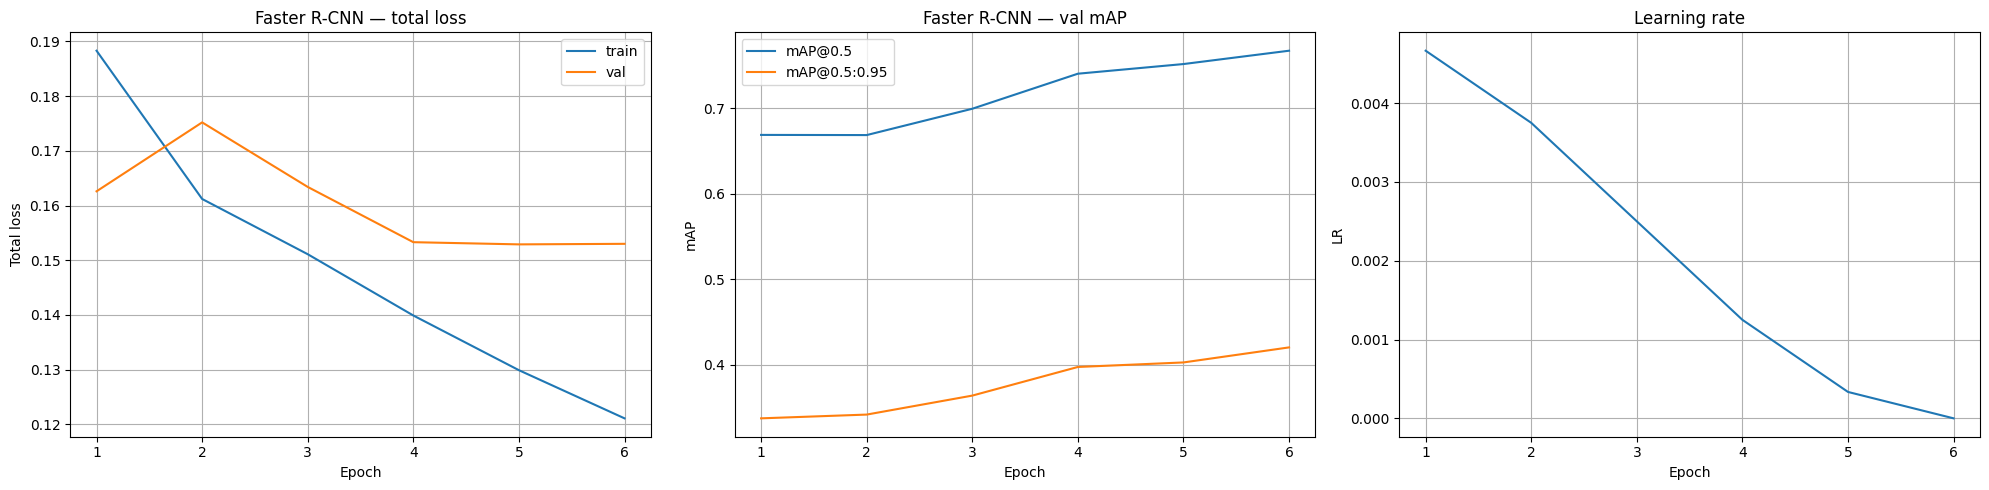

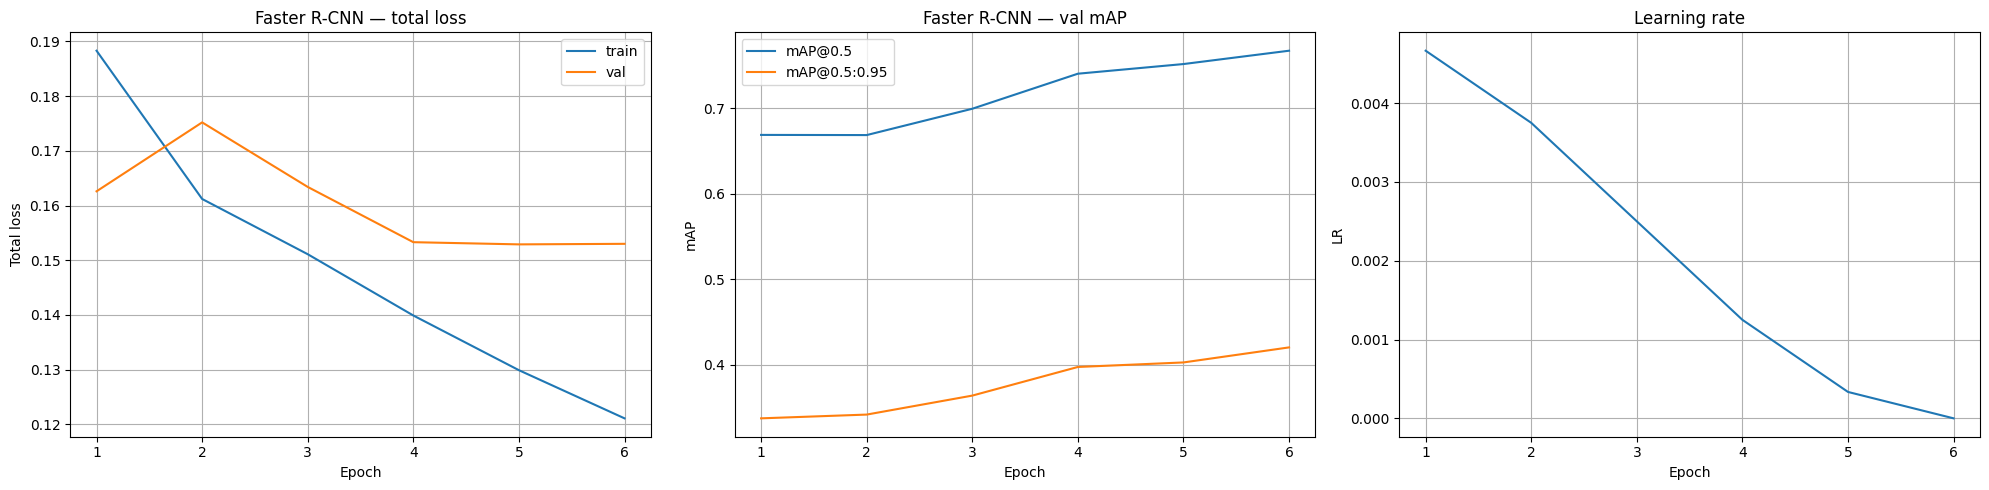

Saved: /content/checkpoints/faster_rcnn/training_curves.png
Saved: /content/checkpoints/faster_rcnn/training_curves.png


In [15]:
import matplotlib.pyplot as plt

hist = json.loads(HISTORY_PATH.read_text())
epochs = [h["epoch"] for h in hist]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- Loss ---
axes[0].plot(epochs, [h["train_loss"] for h in hist], label="train")
axes[0].plot(epochs, [h["val_loss"]   for h in hist], label="val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Total loss")
axes[0].set_title("Faster R-CNN — total loss")
axes[0].legend(); axes[0].grid(True)

# --- mAP ---
axes[1].plot(epochs, [h["val_mAP_0.5"]        for h in hist], label="mAP@0.5")
axes[1].plot(epochs, [h["val_mAP_0.5:0.95"]   for h in hist], label="mAP@0.5:0.95")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("mAP")
axes[1].set_title("Faster R-CNN — val mAP")
axes[1].legend(); axes[1].grid(True)

# --- LR ---
axes[2].plot(epochs, [h["lr"] for h in hist])
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("LR")
axes[2].set_title("Learning rate")
axes[2].grid(True)

plt.tight_layout()
out_png = CKPT_DIR / "training_curves.png"
plt.savefig(out_png, dpi=150)
plt.show()
print(f"Saved: {out_png}")

Loaded best checkpoint from epoch 6 (val mAP@0.5:0.95=0.4204)
Loaded best checkpoint from epoch 6 (val mAP@0.5:0.95=0.4204)


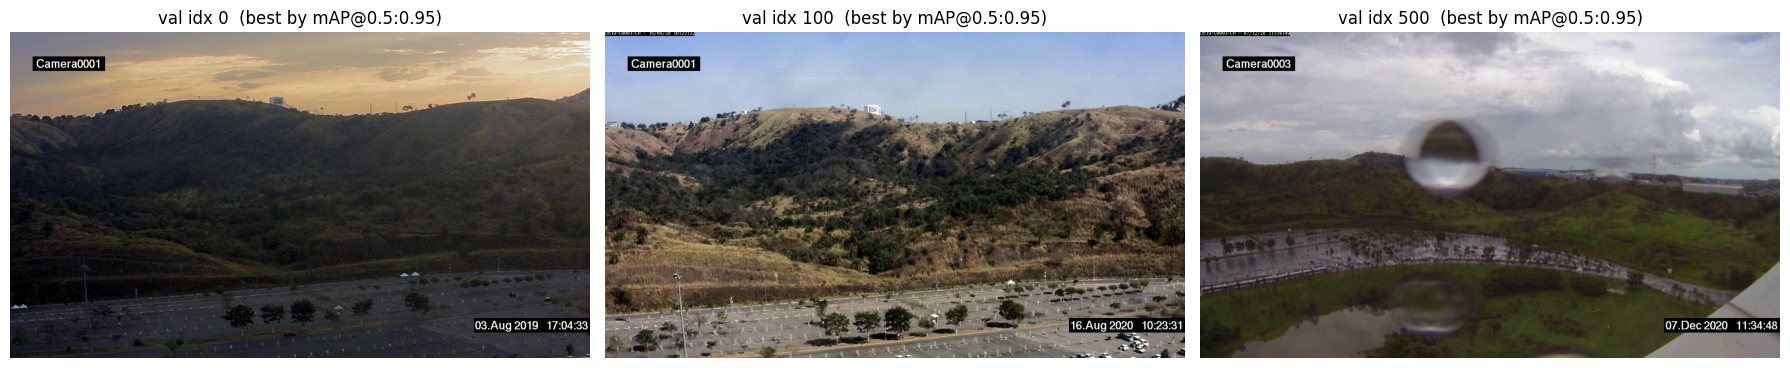

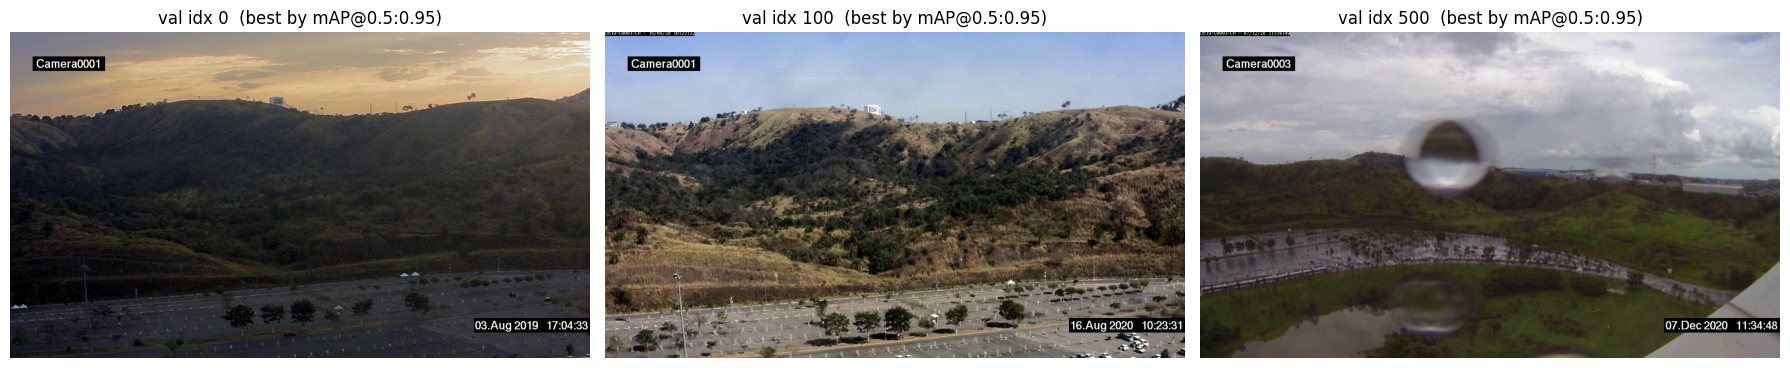

Saved: /content/checkpoints/faster_rcnn/baseline_predictions.png
Saved: /content/checkpoints/faster_rcnn/baseline_predictions.png


In [16]:
import cv2

if BEST_CKPT.exists():
    ckpt = torch.load(BEST_CKPT, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    print(f"Loaded best checkpoint from epoch {ckpt['epoch']} "
          f"(val mAP@0.5:0.95={ckpt.get('best_metric', float('nan')):.4f})")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    with torch.no_grad():
        for ax, idx in zip(axes, [0, 100, 500]):
            img, _ = val_ds[idx]
            out = model([img.to(device)])[0]
            img_np = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8).copy()
            for box, score, label in zip(out["boxes"], out["scores"], out["labels"]):
                if score.item() < 0.5:
                    continue
                x1, y1, x2, y2 = map(int, box.cpu().numpy())
                color = (255, 140, 0) if label.item() == 1 else (255, 0, 0)
                cv2.rectangle(img_np, (x1, y1), (x2, y2), color, 2)
                name = "smoke" if label.item() == 1 else "fire"
                cv2.putText(img_np, f"{name} {score:.2f}", (x1, max(y1 - 5, 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
            ax.imshow(img_np); ax.axis("off")
            ax.set_title(f"val idx {idx}  (best by mAP@0.5:0.95)")
    plt.tight_layout()
    out_png = CKPT_DIR / "baseline_predictions.png"
    plt.savefig(out_png, dpi=150)
    plt.show()
    print(f"Saved: {out_png}")
else:
    print("No best checkpoint found — train first.")

Found 12 positive images
Found 12 positive images


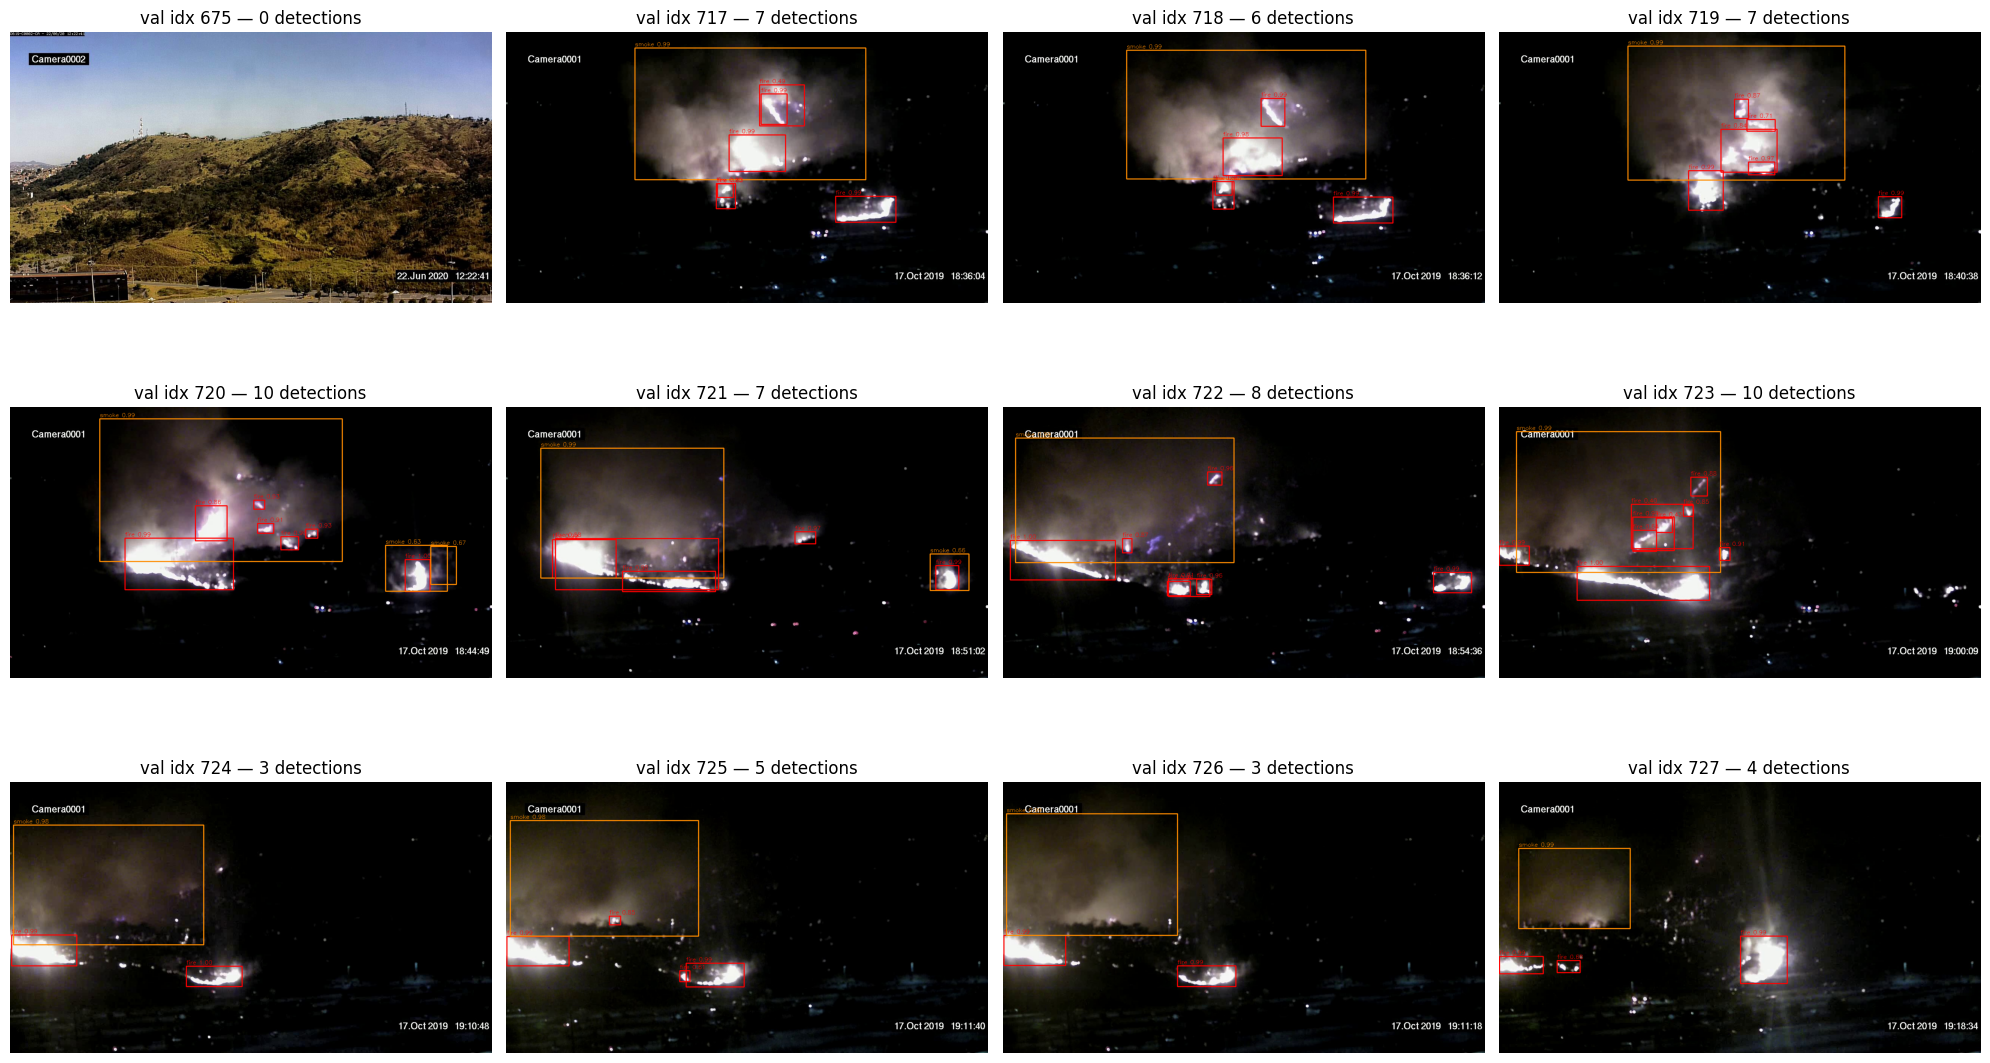

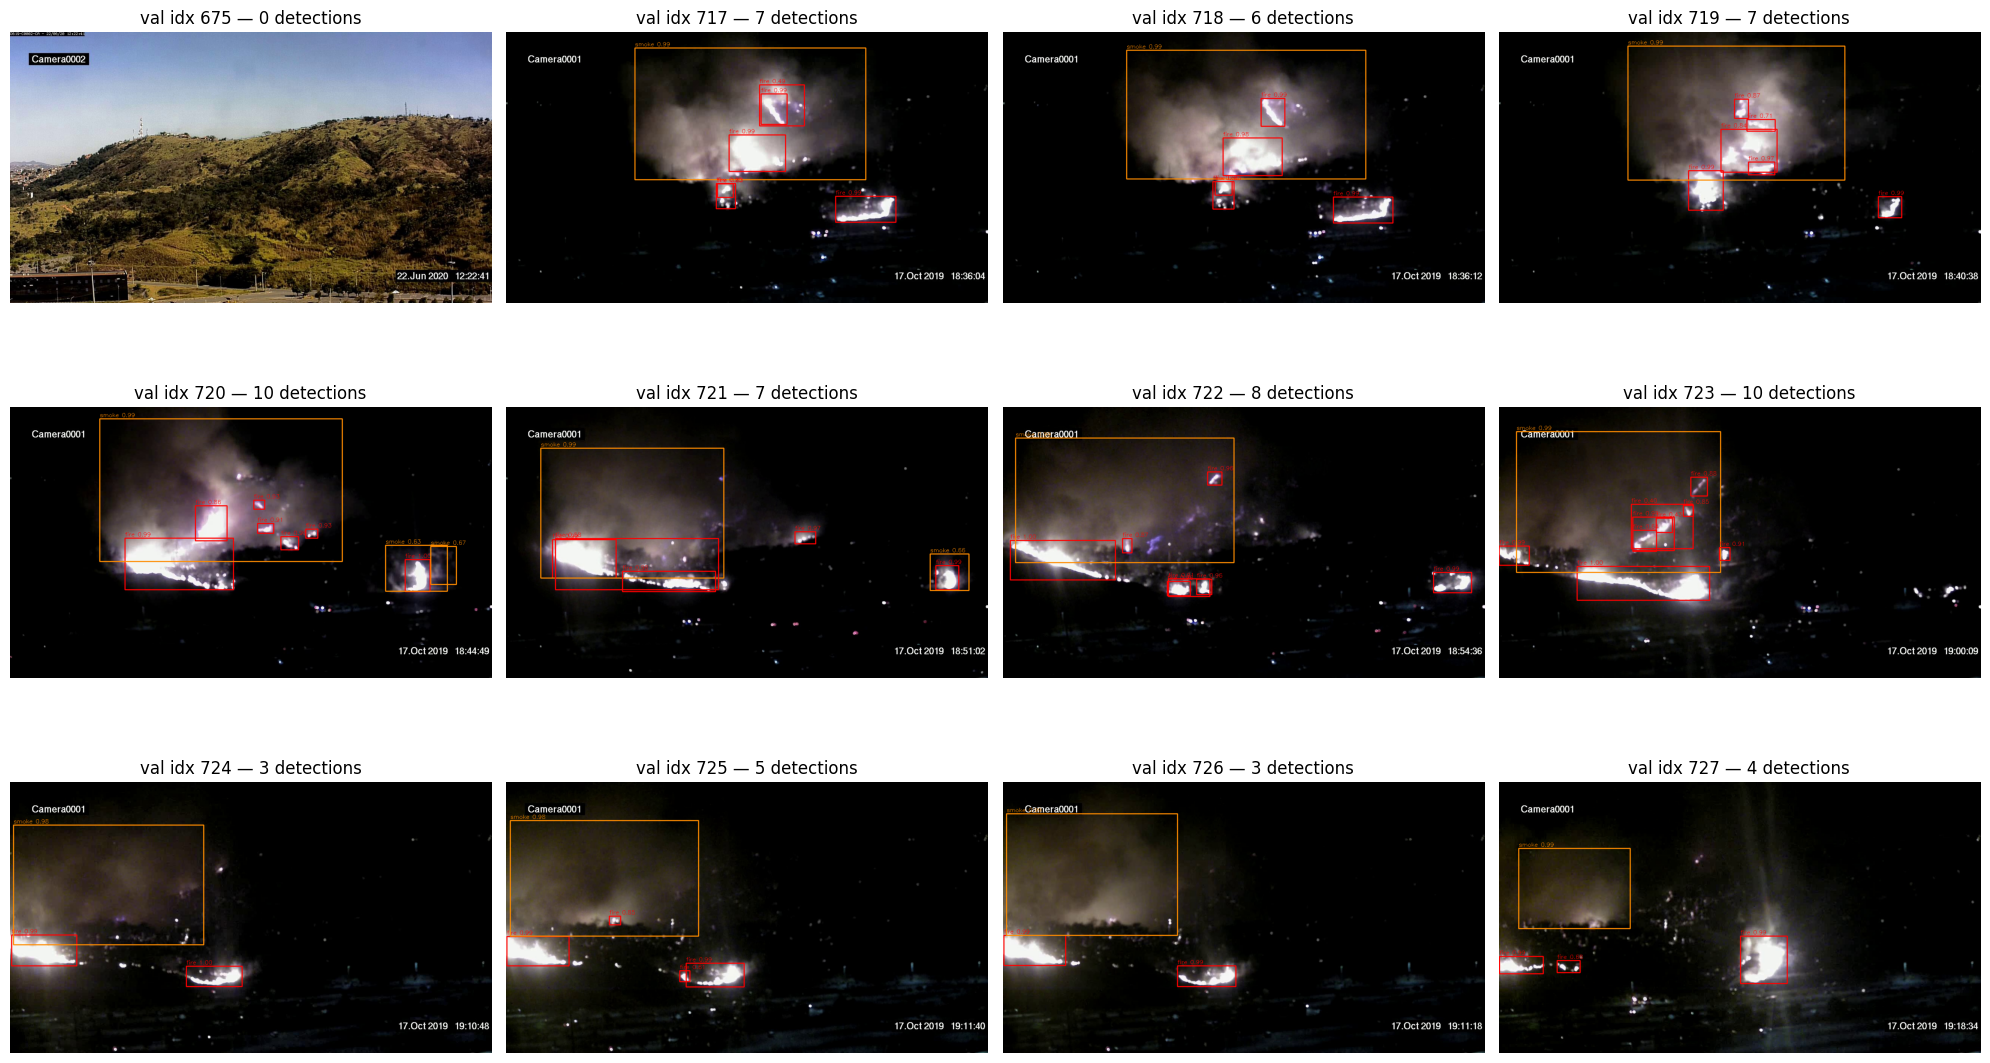

Saved: /content/checkpoints/faster_rcnn/baseline_predictions_positive.png
Saved: /content/checkpoints/faster_rcnn/baseline_predictions_positive.png


In [17]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch

pos_indices = []
for i in range(len(val_ds)):
    _, t = val_ds[i]
    if t["boxes"].shape[0] > 0:
        pos_indices.append(i)
    if len(pos_indices) >= 12:
        break

print(f"Found {len(pos_indices)} positive images")

model.eval()
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

with torch.no_grad():
    for ax, idx in zip(axes, pos_indices):
        img, _ = val_ds[idx]
        out = model([img.to(device)])[0]
        img_np = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8).copy()
        n_drawn = 0
        for box, score, label in zip(out["boxes"], out["scores"], out["labels"]):
            if score.item() < 0.4:
                continue
            x1, y1, x2, y2 = map(int, box.cpu().numpy())
            color = (255, 140, 0) if label.item() == 1 else (255, 0, 0)
            cv2.rectangle(img_np, (x1, y1), (x2, y2), color, 2)
            name = "smoke" if label.item() == 1 else "fire"
            cv2.putText(img_np, f"{name} {score:.2f}", (x1, max(y1-5, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
            n_drawn += 1
        ax.imshow(img_np); ax.axis("off")
        ax.set_title(f"val idx {idx} — {n_drawn} detections")

plt.tight_layout()
out_png = CKPT_DIR / "baseline_predictions_positive.png"
plt.savefig(out_png, dpi=120)
plt.show()
print(f"Saved: {out_png}")